# Clover Leaf

A noisy planar sample of the clover-leaf curve $r = 2.5 + \sin(4.5\theta)$ demonstrates how the Dirichlet-energy regulariser $\lambda$ trades off fidelity against smoothness (Section 4 of the paper).


In [ ]:
from dreimac import CircularCoords
from dreimac.utils import CircleMapUtils
from persim import plot_diagrams
from ripser import ripser
import matplotlib.pyplot as plt
import numpy as np
import torofit as TF

In [16]:

np.random.seed(42)
n_data = 1000

theta = 2*np.pi*np.random.rand(n_data)

rho = 0.5*np.random.randn(n_data)

r = 2.5  + rho + np.sin(4.5*theta)

data = np.array([r*np.cos(theta), r*np.sin(theta)]).T

n_land = 100
res = ripser(data, maxdim=1, n_perm = n_land, coeff =13)
dgms = res['dgms']

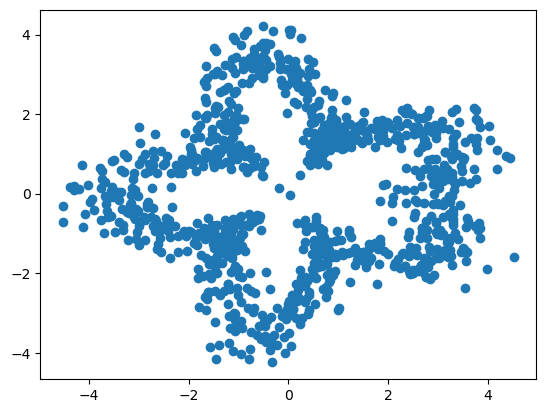

In [17]:
plt.scatter(data[:,0],data[:,1])

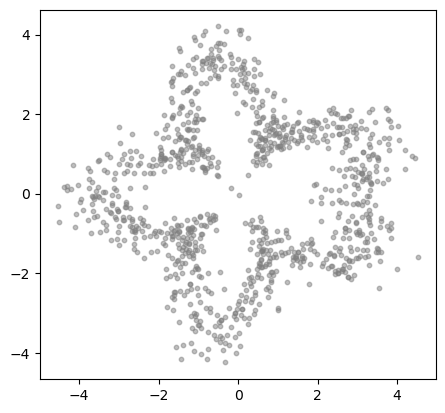

In [18]:
fig, ax = plt.subplots()
ax.scatter(data[:,0], data[:,1], s=10, color='gray', alpha=0.5)
ax.set_aspect('equal')
 

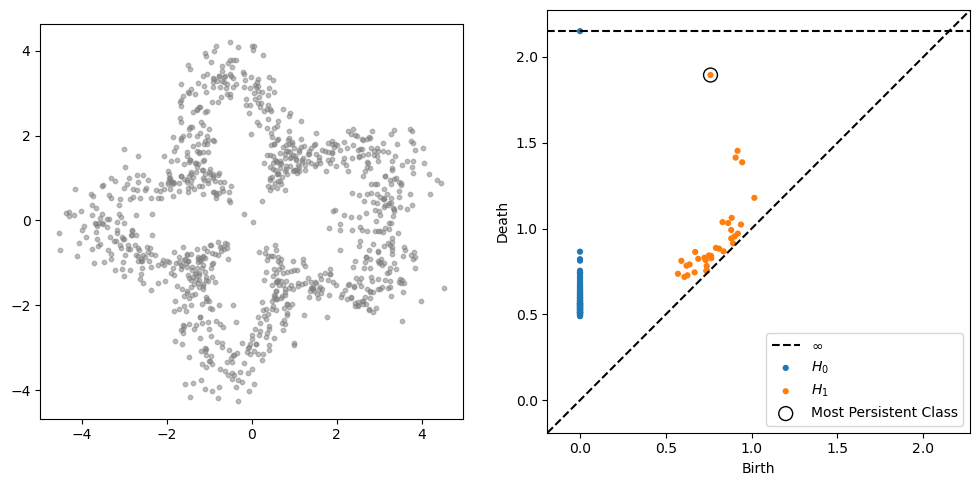

In [19]:
fig, ax = plt.subplots(1,2,figsize=(12,6))
ax[0].scatter(data[:,0], data[:,1], s=10, color='gray', alpha=0.5)
ax[0].set_aspect('equal')
plot_diagrams(dgms, show=False, ax=ax[1])
perm = np.argsort(dgms[1][:,1] - dgms[1][:,0])
target_class = dgms[1][perm[-1]]
ax[1].scatter(target_class[0], target_class[1], marker='o', color='red', s=100, label='Most Persistent Class',  facecolors='none', edgecolors='black')
ax[1].legend()

In [20]:
cc = CircularCoords(data, n_landmarks=n_land)
cc_theta = cc.get_coordinates().reshape(-1,1)

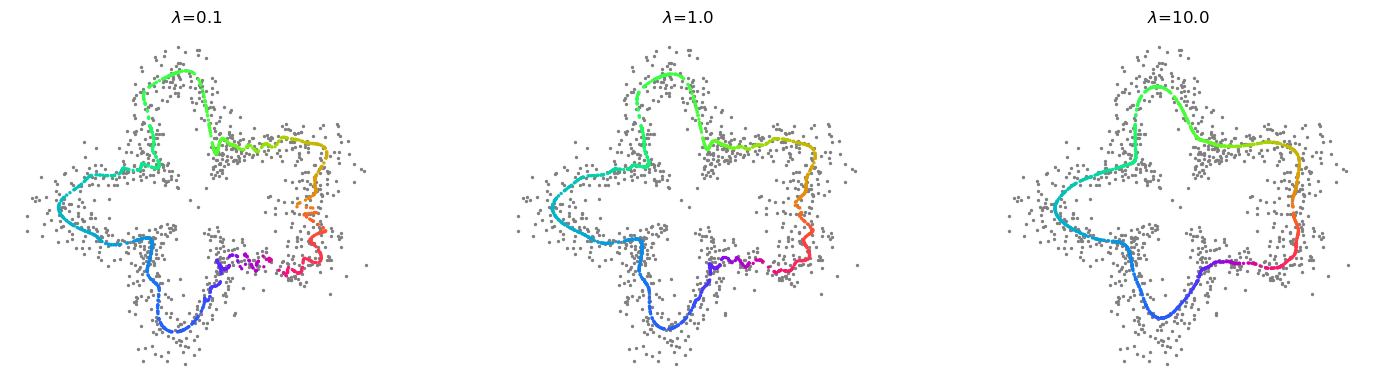

In [22]:
lams = [0.1, 1.0, 10.0]
K = 40
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, lam in enumerate(lams):
    fit = TF.fit(data, cc_theta, K=K, lam=lam)
    res = TF.Toroidal_Evaluate(fit, cc_theta, K=K).real
    axes[i].scatter(data[:,0], data[:,1], s=2, c='gray',alpha=1.0)
    axes[i].scatter(res[:,0], res[:,1], s=2.0, color=CircleMapUtils.to_sinebow(cc_theta[:,0]))
    axes[i].set_title(f'$\lambda$={lam}', fontsize=12)
    axes[i].set_aspect('equal')
    axes[i].axis('off')
plt.tight_layout()
plt.show()